
# Week 4 Capstone — Predicting Internship Selection Outcomes

**Data Science Internship | NextGen Learners**

In this project, we will use applicant data from previous weeks to build a machine learning model that predicts internship selection outcomes.


## Step 1 — Import Required Libraries

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Step 2.1 — Load the Existing Dataset

In [2]:
df = pd.read_csv("applicants_cleaned.csv")

In [3]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Omar Hassan,omar.hassan1@example.com,1.085329e+09,Artificial Intelligence,AUC,2025-08-19,Under Review
1,Nour Khaled,nour.khaled2@example.com,1.038899e+09,Web Development,AUC,2025-06-28,Under Review
2,Sara Ali,sara.ali3@example.com,1.120576e+09,Cyber Security,BUE,2025-03-12,Selected
3,Omar Hassan,omar.hassan4@example.com,1.147309e+09,Web Development,BUE,2026-04-22,Under Review
4,Nour Khaled,nour.khaled5@example.com,1.160930e+09,Cyber Security,Not Specified,2025-11-11,Selected


In [4]:
df.shape

(75, 7)

In [5]:
print("\nDataset Columns:")
print(df.columns.tolist())


Dataset Columns:
['Applicant Name', 'Email', 'Phone', 'Domain Applied', 'University', 'Application Date', 'Status']


## 2.2 Generate Simulated Features

In [6]:
""" To make the dataset more suitable for machine learning, four new features will be added using NumPy.
    Since real historical behavioral data is not available, these features will be simulated with reasonable values.
    A random seed will be set to ensure reproducibility, so the generated values remain consistent every time the notebook is executed.
"""

# Step 2.2 — Generate Simulated Features

# Set random seed for reproducibility
np.random.seed(42)

# Generate number of skills listed (1–8)
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

# Generate portfolio availability
df['has_portfolio'] = np.random.choice(
    ['Yes', 'No'],
    size=len(df),
    p=[0.4, 0.6]
)

# Generate previous hackathon participation
df['prior_hackathon_participation'] = np.random.choice(
    ['Yes', 'No'],
    size=len(df),
    p=[0.3, 0.7]
)

# Generate statement quality score (1–10)
df['statement_quality_score'] = np.random.randint(
    1, 11, size=len(df)
)

In [8]:
# Verify the newly generated features
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Omar Hassan,omar.hassan1@example.com,1.085329e+09,Artificial Intelligence,AUC,2025-08-19,Under Review,7,Yes,No,4
1,Nour Khaled,nour.khaled2@example.com,1.038899e+09,Web Development,AUC,2025-06-28,Under Review,4,Yes,Yes,1
2,Sara Ali,sara.ali3@example.com,1.120576e+09,Cyber Security,BUE,2025-03-12,Selected,5,No,Yes,2
3,Omar Hassan,omar.hassan4@example.com,1.147309e+09,Web Development,BUE,2026-04-22,Under Review,7,No,No,1
4,Nour Khaled,nour.khaled5@example.com,1.160930e+09,Cyber Security,Not Specified,2025-11-11,Selected,3,No,Yes,5


In [9]:
df.shape

(75, 11)

In [10]:
print("\nNew Features:")
print(df[['num_skills_listed',
          'has_portfolio',
          'prior_hackathon_participation',
          'statement_quality_score']].describe(include='all'))


New Features:
        num_skills_listed has_portfolio prior_hackathon_participation  \
count           75.000000            75                            75   
unique                NaN             2                             2   
top                   NaN            No                            No   
freq                  NaN            47                            50   
mean             4.573333           NaN                           NaN   
std              2.206706           NaN                           NaN   
min              1.000000           NaN                           NaN   
25%              3.000000           NaN                           NaN   
50%              4.000000           NaN                           NaN   
75%              6.500000           NaN                           NaN   
max              8.000000           NaN                           NaN   

        statement_quality_score  
count                 75.000000  
unique                      NaN  
top   

## 3.1 — Convert Yes/No Columns to 0/1

In [11]:
"""
Machine learning models require numerical input rather than text categories.
Therefore, the `has_portfolio` and `prior_hackathon_participation` columns will be converted into binary numerical values:
- Yes → 1
- No → 0
This allows the models to process these features mathematically.
"""

# Step 3.1 — Convert Yes/No Columns to 0/1

df['has_portfolio'] = df['has_portfolio'].map({
    'Yes': 1,
    'No': 0
})

df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({
    'Yes': 1,
    'No': 0
})

In [12]:
df['has_portfolio'].value_counts()

has_portfolio
0    47
1    28
Name: count, dtype: int64

In [13]:
df['prior_hackathon_participation'].value_counts()

prior_hackathon_participation
0    50
1    25
Name: count, dtype: int64

In [14]:
df[['has_portfolio','prior_hackathon_participation']].dtypes

has_portfolio                    int64
prior_hackathon_participation    int64
dtype: object

## 3.2 — Create the Target Column

In [15]:
"""
The target variable represents the outcome we want the machine learning model to predict.
The Status column will be converted into a binary target:
- Selected → 1
- Rejected → 0
- Under Review → 0
This creates a binary classification problem where the model predicts whether an applicant was selected or not.
"""
# Step 3.2 — Create Target Column

df['target'] = df['Status'].apply(
    lambda x: 1 if x == 'Selected' else 0
)

In [16]:
df['target'].value_counts()

target
0    57
1    18
Name: count, dtype: int64

#### Remove Applicants With Pending Status

In [17]:
# Remove applicants with pending decisions

df_model = df[df['Status'] != 'Under Review'].copy()

print("Original Dataset Shape:", df.shape)
print("Model Dataset Shape:", df_model.shape)

print("\nConfirmed Target Distribution:")
print(df_model['target'].value_counts())

Original Dataset Shape: (75, 12)
Model Dataset Shape: (43, 12)

Confirmed Target Distribution:
target
0    25
1    18
Name: count, dtype: int64


## 3.3 — One-Hot Encoding

In [18]:
# Step 3.3 — One-Hot Encoding

df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True
)

In [19]:
df_model.head()

,Applicant Name,Email,Phone,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,target,Domain Applied_Cyber Security,Domain Applied_Data Science,Domain Applied_UI/UX,Domain Applied_Web Development
2,Sara Ali,sara.ali3@example.com,1.120576e+09,BUE,2025-03-12,Selected,5,0,1,2,1,True,False,False,False
4,Nour Khaled,nour.khaled5@example.com,1.160930e+09,Not Specified,2025-11-11,Selected,3,0,1,5,1,True,False,False,False
5,Hana Mostafa,not_provided@example.com,1.252235e+09,Zagazig University,2025-05-05,Rejected,8,1,0,5,0,False,False,True,False
6,Jana Sameh,jana.sameh7@example.com,1.139437e+09,Ain Shams University,2025-05-02,Rejected,5,1,0,7,0,False,False,False,False
7,Ahmed Mohamed,ahmed.duplicate@example.com,1.012346e+09,Cairo University,2026-12-05,Selected,5,1,0,9,1,False,False,False,True


In [20]:
df_model.shape

(43, 15)

In [21]:
df_model.columns.tolist()

['Applicant Name',
 'Email',
 'Phone',
 'University',
 'Application Date',
 'Status',
 'num_skills_listed',
 'has_portfolio',
 'prior_hackathon_participation',
 'statement_quality_score',
 'target',
 'Domain Applied_Cyber Security',
 'Domain Applied_Data Science',
 'Domain Applied_UI/UX',
 'Domain Applied_Web Development']

## 3.4 — Select Final Feature Set

In [23]:
# Step 3.4 — Select Final Feature Set

feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

# Define Features (X) and Target (y)
X = df_model[feature_columns]
y = df_model['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (43, 8)
Target Shape: (43,)

Feature Columns:
['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Cyber Security', 'Domain Applied_Data Science', 'Domain Applied_UI/UX', 'Domain Applied_Web Development']

Target Distribution:
target
0    25
1    18
Name: count, dtype: int64


## Step 4 — Train/Test Split

In [24]:
# Step 4 — Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (34, 8)
Testing Features Shape: (9, 8)

Training Target Shape: (34,)
Testing Target Shape: (9,)


## 5.1 — Create a Reusable Model Evaluation Function

In [26]:
# Step 5.1 — Create a Reusable Model Evaluation Function

def apply_model(model):

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Training Classification Report
    print("Train Classification Report:")
    print(classification_report(
        y_train,
        train_pred,
        zero_division=0
    ))

    # Testing Classification Report
    print("Test Classification Report:")
    print(classification_report(
        y_test,
        test_pred,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(y_test, test_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Selected', 'Selected'],
        yticklabels=['Not Selected', 'Selected']
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

    return test_pred

Train Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.86      0.82        21
           1       0.73      0.62      0.67        13

    accuracy                           0.76        34
   macro avg       0.75      0.74      0.74        34
weighted avg       0.76      0.76      0.76        34

Test Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.75      0.50         4
           1       0.00      0.00      0.00         5

    accuracy                           0.33         9
   macro avg       0.19      0.38      0.25         9
weighted avg       0.17      0.33      0.22         9



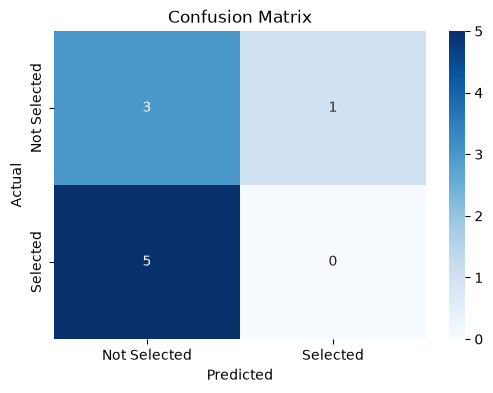

In [27]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_predictions = apply_model(lr_model)

Train Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        21
           1       0.87      1.00      0.93        13

    accuracy                           0.94        34
   macro avg       0.93      0.95      0.94        34
weighted avg       0.95      0.94      0.94        34

Test Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         4
           1       0.60      0.60      0.60         5

    accuracy                           0.56         9
   macro avg       0.55      0.55      0.55         9
weighted avg       0.56      0.56      0.56         9



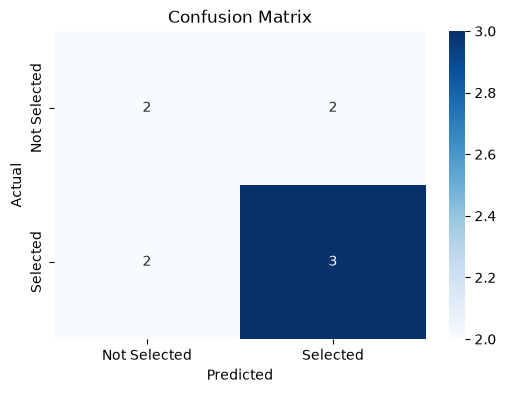

In [28]:
# Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
dt_predictions = apply_model(dt_model)

Train Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.71      0.75        21
           1       0.60      0.69      0.64        13

    accuracy                           0.71        34
   macro avg       0.69      0.70      0.70        34
weighted avg       0.72      0.71      0.71        34

Test Classification Report:
              precision    recall  f1-score   support

           0       0.57      1.00      0.73         4
           1       1.00      0.40      0.57         5

    accuracy                           0.67         9
   macro avg       0.79      0.70      0.65         9
weighted avg       0.81      0.67      0.64         9



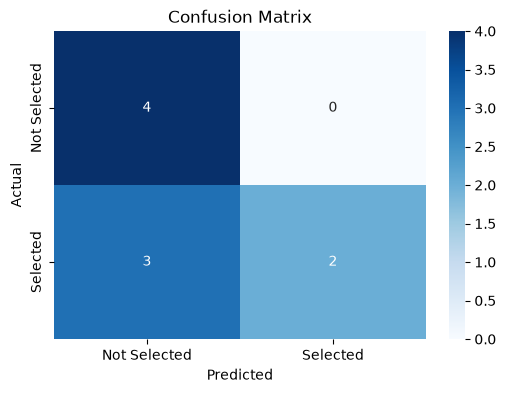

In [31]:
# K-Nearest Neighbors
knn = KNeighborsClassifier()
knn_predictions = apply_model(knn)

## 6.1 — Accuracy

In [32]:
# Step 6.1 — Model Accuracy Comparison

models_predictions = {
    'Logistic Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'KNN': knn_predictions
}

accuracy_results = []

for model_name, predictions in models_predictions.items():

    accuracy = accuracy_score(y_test, predictions)

    accuracy_results.append({
        'Model': model_name,
        'Accuracy': f'{accuracy:.2%}'
    })

accuracy_df = pd.DataFrame(accuracy_results)

accuracy_df

,Model,Accuracy
0,Logistic Regression,33.33%
1,Decision Tree,55.56%
2,KNN,66.67%



**Accuracy Interpretation:**

KNN achieved the highest accuracy of 66.67%, followed by Decision Tree with 55.56%, while Logistic Regression achieved 33.33%.

However, the test dataset contains only 9 applicants, so these results should be interpreted cautiously. Accuracy alone is not sufficient to determine the best-performing model.


## Step 6.2 — Compare Precision and Recall

In [33]:
# Step 6.2 — Compare Precision and Recall

models_predictions = {
    'Logistic Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'KNN': knn_predictions
}

evaluation_results = []

for model_name, predictions in models_predictions.items():

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    evaluation_results.append({
        'Model': model_name,
        'Precision': round(precision * 100, 2),
        'Recall': round(recall * 100, 2)
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Model,Precision,Recall
0,Logistic Regression,0.0,0.0
1,Decision Tree,60.0,60.0
2,KNN,100.0,40.0



**Precision and Recall Interpretation:**

- Logistic Regression achieved 0% Precision and 0% Recall, meaning it failed to correctly identify any selected applicants in the test set.
- Decision Tree achieved 60% Precision and 60% Recall, showing a more balanced performance between identifying selected applicants and avoiding incorrect positive predictions.
- KNN achieved 100% Precision but only 40% Recall. This means all applicants predicted as Selected were actually selected, but the model missed 3 out of 5 selected applicants.

These results show that evaluating a model using multiple metrics provides a better understanding of its performance than accuracy alone.



**Confusion Matrix Interpretation:**

- **Logistic Regression:** Correctly identified 3 Not Selected applicants but failed to identify any Selected applicants.
- **Decision Tree:** Correctly classified 2 Not Selected applicants and 3 Selected applicants, while making 4 incorrect predictions.
- **KNN:** Correctly classified 4 Not Selected applicants and 2 Selected applicants, but missed 3 Selected applicants.

The confusion matrices highlight the types of prediction errors made by each model.


## 6.3 — Model Limitations

Although the models were successfully trained and evaluated, several limitations should be considered:

1. **Small Dataset:** The dataset contains only 43 applicants with confirmed outcomes, which limits the models' ability to learn general patterns.

2. **Simulated Features:** Four features were generated using random values rather than collected from real applicants. This may introduce artificial patterns that do not represent real selection behavior.

3. **Limited Features:** The model uses only eight input features, which may not capture all factors influencing internship selection decisions.

4. **Potential Overfitting:** The Decision Tree achieved 94% training accuracy compared to 55.56% testing accuracy, indicating possible overfitting.

5. **Limited Evaluation:** The models were evaluated using a single train/test split with only nine testing samples. Therefore, the reported metrics may not reliably represent performance on unseen real-world data.

**Conclusion:**

The current models are suitable for educational and experimental purposes only. More real historical applicant data, meaningful features, and further validation are required before using these models for actual internship selection decisions.

## Step 7 — Interpret: Which Features Mattered Most?

In [34]:
# Step 7 — Calculate Feature Importance

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
3,statement_quality_score,0.516578
0,num_skills_listed,0.271803
2,prior_hackathon_participation,0.122370
1,has_portfolio,0.089250
4,Domain Applied_Cyber Security,0.000000
5,Domain Applied_Data Science,0.000000
6,Domain Applied_UI/UX,0.000000
7,Domain Applied_Web Development,0.000000


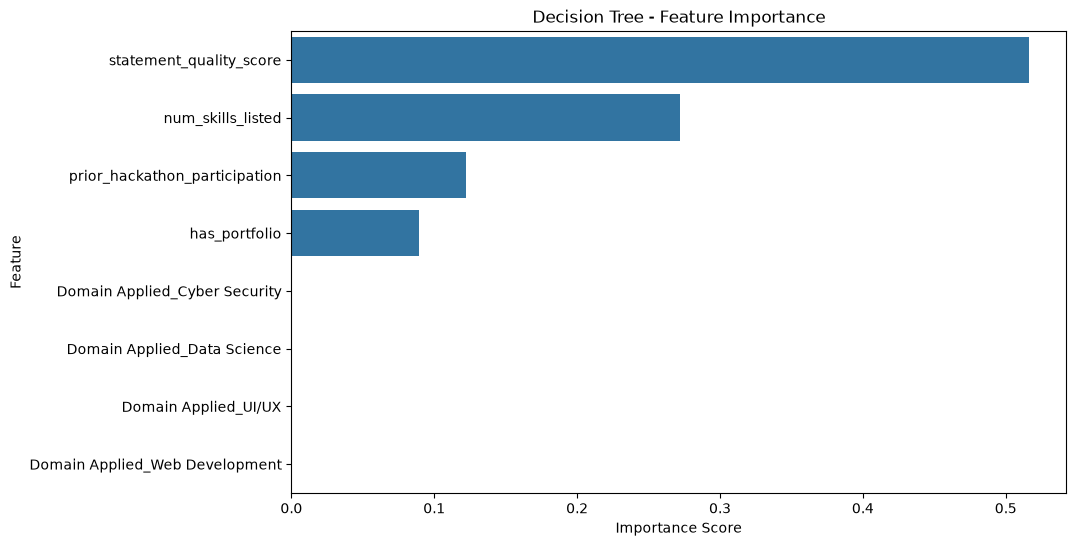

In [35]:
# Visualize Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Decision Tree - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()


### Feature Importance Interpretation

The Decision Tree Feature Importance analysis revealed the following:

- **statement_quality_score (51.66%):** The most important feature, contributing the most to the model's decision-making process.
- **num_skills_listed (27.18%):** The second most important feature.
- **prior_hackathon_participation (12.24%):** Had a moderate contribution.
- **has_portfolio (8.93%):** Had a smaller contribution compared to the other numerical features.
- **Domain Features (0%):** All encoded domain features had zero importance in the trained Decision Tree.

**Conclusion:**

The model relied mainly on statement quality and the number of skills listed when making predictions.

However, these findings reflect the model's behavior on the current simulated dataset and should not be interpreted as real-world internship selection criteria.


## Executive Summary



**What we did:**

We developed a machine learning project to explore the factors associated with internship selection outcomes at NextGenLearners. Using the previously cleaned applicant dataset, we prepared the data, introduced additional features, and trained multiple prediction models to identify potential patterns in applicant selection.

**What we found:**

Among the tested models, K-Nearest Neighbors achieved the highest test accuracy of 66.67%, followed by Decision Tree at 55.56%. The Decision Tree analysis showed that the applicant's written statement quality and number of listed skills were the most influential features in its predictions.

**Important caveats:**

This analysis was based on a small dataset of 43 applicants with confirmed outcomes, and four additional features were artificially generated for this exercise rather than collected from real historical applications. Therefore, the results represent patterns learned from this dataset and should not be considered evidence of NextGenLearners' actual selection criteria. Further validation using a larger dataset of real applicant records is necessary. The model should only support human reviewers and must never replace human judgment, especially because it may reproduce biases present in historical decisions.

**Recommendation:**

We recommend collecting consistent, real applicant information, particularly regarding written statement quality, skills, portfolios, and previous hackathon participation. This would help build a more reliable dataset and allow future models to be properly validated before being considered for decision-support purposes.